# 02 - Model and validation

Trains the Random Forest that separates vegetation from non-vegetation, pixel by pixel, using the hand-drawn masks of the C1-C9 tiles.

The model is evaluated in three ways, from the most optimistic to the most honest:

1. **Random split:** 80/20 of the pixels at random (the original evaluation). Neighbouring pixels of the same tile end up in train and test, and the 3x3 filter mixes them, so this split leaks information and overestimates the accuracy.
2. **By tile:** all the pixels of a tile are either in train or in test (5 folds).
3. **By quadrant:** the model is trained with 8 quadrants and tested on the one it never saw (9 folds). This is the closest to applying the model to a new area.

It is also compared against the simplest possible rule, **NDVI > 0.3** (the first attempt of the project), to check whether the model adds value.

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split,GroupKFold,LeaveOneGroupOut
from sklearn.metrics import (confusion_matrix,classification_report,accuracy_score,balanced_accuracy_score,
                             recall_score,precision_score,f1_score)

from config import trainImagesFolder,trainMasksFolder,resultsFolder,validationFolder,modelsFolder
from utils import readImage,featureNames

# Some tiles only have one class, sklearn warns about it but the metrics are still valid
warnings.filterwarnings('ignore',category=UserWarning)

resultsFolder.mkdir(exist_ok=True)

## Pixel dataset
Every labeled pixel of the masks (1 = vegetation, 0 = no vegetation, -1 = unlabeled is ignored). Each pixel also keeps the tile and quadrant it comes from, needed for the validation by groups.

In [2]:
quadrants=['C1','C2','C3','C4','C5','C6','C7','C8','C9']

maskPattern=re.compile(r'mask_(C\d)_(R\d{2})_(C\d{2})\.tif',re.IGNORECASE)

xList=[]
yList=[]
tileList=[]
quadList=[]

for quad in quadrants:
    maskPaths=sorted(trainMasksFolder.glob(f'mask_{quad}_R*_C*.tif'))
    print(f'Quadrant {quad} - masks found: {len(maskPaths)}')

    for maskPath in maskPaths:
        m=maskPattern.match(maskPath.name)
        row=m.group(2).upper()
        col=m.group(3).upper()

        imgPath=trainImagesFolder/quad/f'Sentinel_Monterrey_15x15_{row}_{col}.tif'
        if not imgPath.exists():
            print(f'  Image not found for {maskPath.name}')
            continue

        img,profile=readImage(imgPath)   # (H,W,13)

        with rasterio.open(maskPath) as mskSrc:
            yMask=mskSrc.read(1)

        if yMask.shape!=img.shape[:2]:
            raise ValueError(f'Image and mask sizes do not match: {maskPath.name}')

        maskTrain=(yMask>=0)
        n=maskTrain.sum()
        if n==0:
            print(f'  {maskPath.name}: no labeled pixels, skipped')
            continue

        xList.append(img[maskTrain])
        yList.append(yMask[maskTrain].astype(np.uint8))
        tileList.append(np.full(n,f'{quad}_{row}_{col}'))
        quadList.append(np.full(n,quad))

xAll=np.vstack(xList)
yAll=np.concatenate(yList)
tileAll=np.concatenate(tileList)
quadAll=np.concatenate(quadList)

print('\nTotal labeled pixels:',xAll.shape[0])
print('Tiles with labels:',len(set(tileAll)))

Quadrant C1 - masks found: 3
Quadrant C2 - masks found: 6
Quadrant C3 - masks found: 4
  mask_C3_R05_C05.tif: no labeled pixels, skipped
Quadrant C4 - masks found: 6
Quadrant C5 - masks found: 12
Quadrant C6 - masks found: 6
Quadrant C7 - masks found: 3
Quadrant C8 - masks found: 6
Quadrant C9 - masks found: 3

Total labeled pixels: 1138928
Tiles with labels: 48


Labels by quadrant. Most of the non-vegetation labels are in C5 (urban center) and C1, C2 and C9 only have vegetation labels, which matters when reading the results by quadrant.

In [3]:
labelTable=pd.crosstab(quadAll,yAll,rownames=['quadrant'],colnames=['label']).rename(columns={0:'no veg',1:'veg'})
labelTable.loc['Total']=labelTable.sum()
labelTable['% no veg']=(100*labelTable['no veg']/(labelTable['no veg']+labelTable['veg'])).round(1)
labelTable

label,no veg,veg,% no veg
quadrant,,,
C1,0,78278,0.0
C2,0,194656,0.0
C3,2542,59210,4.1
C4,13355,87935,13.2
C5,229338,129974,63.8
C6,29182,81649,26.3
C7,1573,57276,2.7
C8,9777,96199,9.2
C9,0,67984,0.0


## Model and metrics

In [4]:
def makeModel():
    return RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        n_jobs=-1,
        random_state=42,
        class_weight='balanced'
    )

def getMetrics(yTrue,yPred):
    # class 0 = no vegetation, class 1 = vegetation
    return {
        'n':len(yTrue),
        'accuracy':accuracy_score(yTrue,yPred),
        'balanced_accuracy':balanced_accuracy_score(yTrue,yPred),
        'recall_noveg':recall_score(yTrue,yPred,pos_label=0,zero_division=0),
        'precision_noveg':precision_score(yTrue,yPred,pos_label=0,zero_division=0),
        'f1_noveg':f1_score(yTrue,yPred,pos_label=0,zero_division=0),
        'recall_veg':recall_score(yTrue,yPred,pos_label=1,zero_division=0),
        'precision_veg':precision_score(yTrue,yPred,pos_label=1,zero_division=0),
        'f1_veg':f1_score(yTrue,yPred,pos_label=1,zero_division=0),
    }

## Validation 1: random split (original)

In [5]:
xTr,xVal,yTr,yVal=train_test_split(
    xAll,yAll,
    test_size=0.2,
    stratify=yAll,
    random_state=42
)

clfRandom=makeModel()
clfRandom.fit(xTr,yTr)
yPredRandom=clfRandom.predict(xVal)

print('Confusion matrix (random split):')
print(confusion_matrix(yVal,yPredRandom))
print(classification_report(yVal,yPredRandom,digits=3))

Confusion matrix (random split):
[[ 53667   3487]
 [  3019 167613]]
              precision    recall  f1-score   support

           0      0.947     0.939     0.943     57154
           1      0.980     0.982     0.981    170632

    accuracy                          0.971    227786
   macro avg      0.963     0.961     0.962    227786
weighted avg      0.971     0.971     0.971    227786



## Validation 2 and 3: by tile and by quadrant
Out-of-fold predictions: every pixel is predicted by a model that never saw its tile (or quadrant). The metrics are computed over all the pixels at once.

Each one takes around 40 min, the predictions are saved so the next run only loads them.

In [6]:
def groupValidation(splitter,groups,name):
    '''
    Returns the out-of-fold prediction of every pixel
    '''
    outPath=validationFolder/f'oof_{name}.npy'
    if outPath.exists():
        print('Loading saved predictions:',outPath)
        return np.load(outPath)

    oof=np.zeros_like(yAll)
    for k,(trIdx,teIdx) in enumerate(splitter.split(xAll,yAll,groups)):
        clf=makeModel()
        clf.fit(xAll[trIdx],yAll[trIdx])
        oof[teIdx]=clf.predict(xAll[teIdx])
        print(f'  fold {k}: held out {sorted(set(groups[teIdx].tolist()))}')

    validationFolder.mkdir(parents=True,exist_ok=True)
    np.save(outPath,oof)
    return oof

oofTile=groupValidation(GroupKFold(n_splits=5),tileAll,'tile')
oofQuad=groupValidation(LeaveOneGroupOut(),quadAll,'quadrant')

  fold 0: held out ['C3_R13_C04', 'C4_R02_C11', 'C4_R10_C15', 'C4_R12_C14', 'C5_R07_C04', 'C5_R13_C03', 'C7_R02_C13', 'C8_R05_C02', 'C8_R07_C12']
  fold 1: held out ['C2_R05_C04', 'C2_R06_C04', 'C4_R08_C08', 'C5_R08_C06', 'C5_R08_C10', 'C5_R14_C05', 'C6_R10_C06', 'C6_R14_C09', 'C7_R13_C15', 'C9_R09_C11']
  fold 2: held out ['C1_R11_C03', 'C2_R10_C14', 'C3_R12_C11', 'C4_R05_C10', 'C4_R13_C05', 'C5_R05_C02', 'C5_R15_C10', 'C6_R02_C10', 'C6_R05_C12', 'C8_R12_C12']
  fold 3: held out ['C1_R01_C04', 'C2_R11_C10', 'C2_R15_C11', 'C3_R13_C14', 'C5_R11_C10', 'C5_R12_C11', 'C7_R06_C01', 'C8_R15_C03', 'C9_R06_C08', 'C9_R14_C12']
  fold 4: held out ['C1_R09_C14', 'C2_R05_C15', 'C5_R02_C08', 'C5_R06_C04', 'C5_R12_C12', 'C6_R08_C11', 'C6_R11_C11', 'C8_R07_C01', 'C8_R13_C14']
  fold 0: held out ['C1']
  fold 1: held out ['C2']
  fold 2: held out ['C3']
  fold 3: held out ['C4']
  fold 4: held out ['C5']
  fold 5: held out ['C6']
  fold 6: held out ['C7']
  fold 7: held out ['C8']
  fold 8: held out [

## Baseline: NDVI > 0.3
No training needed, so it is evaluated on all the labeled pixels.

In [7]:
ndviPred=(xAll[:,featureNames.index('NDVI')]>0.3).astype(np.uint8)

## Results

In [8]:
summary=pd.DataFrame({
    'random split':getMetrics(yVal,yPredRandom),
    'by tile':getMetrics(yAll,oofTile),
    'by quadrant':getMetrics(yAll,oofQuad),
    'NDVI > 0.3':getMetrics(yAll,ndviPred),
}).T

summary.to_csv(resultsFolder/'validation_summary.csv',float_format='%.4f')
summary.round(3)

,n,accuracy,balanced_accuracy,recall_noveg,precision_noveg,f1_noveg,recall_veg,precision_veg,f1_veg
random split,227786.0,0.971,0.961,0.939,0.947,0.943,0.982,0.980,0.981
by tile,1138928.0,0.957,0.940,0.908,0.919,0.913,0.973,0.969,0.971
by quadrant,1138928.0,0.948,0.917,0.855,0.930,0.891,0.978,0.953,0.965
NDVI > 0.3,1138928.0,0.954,0.942,0.918,0.902,0.910,0.966,0.972,0.969


Results for each quadrant when it is left out. Where a quadrant has no non-vegetation labels (C1, C2, C9) the balanced accuracy is only the recall of vegetation.

In [9]:
rows=[]
for quad in quadrants:
    sel=quadAll==quad
    rows.append({
        'quadrant':quad,
        'pixels':sel.sum(),
        'no veg pixels':(yAll[sel]==0).sum(),
        'RF balanced acc':balanced_accuracy_score(yAll[sel],oofQuad[sel]),
        'NDVI balanced acc':balanced_accuracy_score(yAll[sel],ndviPred[sel]),
        'RF recall no veg':recall_score(yAll[sel],oofQuad[sel],pos_label=0,zero_division=0),
        'NDVI recall no veg':recall_score(yAll[sel],ndviPred[sel],pos_label=0,zero_division=0),
    })

perQuadrant=pd.DataFrame(rows).set_index('quadrant')
perQuadrant.to_csv(resultsFolder/'validation_by_quadrant.csv',float_format='%.4f')
perQuadrant.round(3)

,pixels,no veg pixels,RF balanced acc,NDVI balanced acc,RF recall no veg,NDVI recall no veg
quadrant,,,,,,
C1,78278,0,0.990,0.963,0.000,0.000
C2,194656,0,1.000,1.000,0.000,0.000
C3,61752,2542,0.942,0.959,0.892,0.926
C4,101290,13355,0.794,0.790,0.611,0.616
C5,359312,229338,0.900,0.911,0.881,0.950
C6,110831,29182,0.911,0.931,0.823,0.870
C7,58849,1573,0.810,0.972,0.647,0.987
C8,105976,9777,0.844,0.860,0.693,0.730
C9,67984,0,0.967,0.980,0.000,0.000


Normalized confusion matrices: random split vs leaving out a whole quadrant

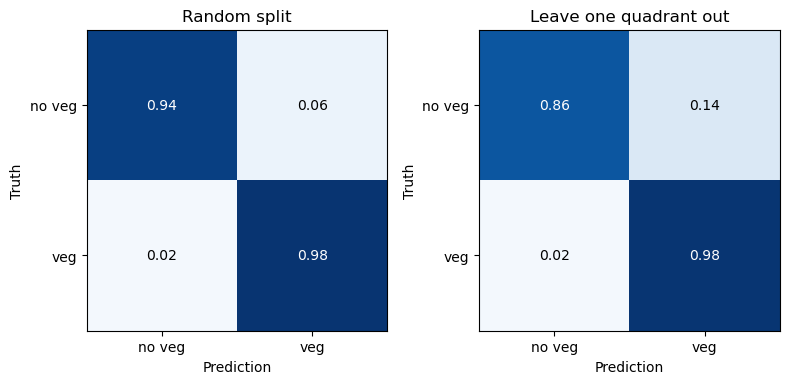

In [10]:
def plotConfusion(ax,yTrue,yPred,title):
    cm=confusion_matrix(yTrue,yPred)
    cmNorm=cm.astype(np.float32)/cm.sum(axis=1,keepdims=True)
    ax.imshow(cmNorm,cmap='Blues',vmin=0,vmax=1)
    ax.set_xticks([0,1])
    ax.set_yticks([0,1])
    ax.set_xticklabels(['no veg','veg'])
    ax.set_yticklabels(['no veg','veg'])
    ax.set_xlabel('Prediction')
    ax.set_ylabel('Truth')
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            val=cmNorm[i,j]
            ax.text(j,i,f'{val:.2f}',ha='center',va='center',color='white' if val>0.5 else 'black')

fig,axes=plt.subplots(1,2,figsize=(8,4))
plotConfusion(axes[0],yVal,yPredRandom,'Random split')
plotConfusion(axes[1],yAll,oofQuad,'Leave one quadrant out')
plt.tight_layout()
plt.savefig(resultsFolder/'confusion_matrices.png',dpi=200)
plt.show()

## Final model
Trained with all the labeled pixels and used in `03_prediction.ipynb`.

In [11]:
clf1=makeModel()
clf1.fit(xAll,yAll)

modelsFolder.mkdir(parents=True,exist_ok=True)
joblib.dump(clf1,modelsFolder/'clf1.joblib')
print('Model saved:',modelsFolder/'clf1.joblib')

Model saved: /Users/arturobenavides/Desktop/urban-green-analysis-v2/data/processed/models/clf1.joblib


Feature importance

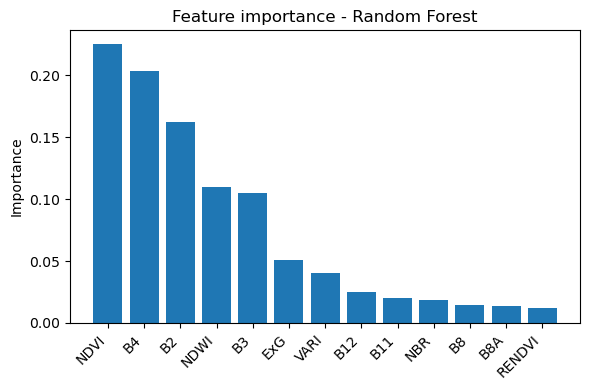

In [12]:
importances=clf1.feature_importances_
idx=np.argsort(importances)[::-1]

fig,ax=plt.subplots(figsize=(6,4))
ax.bar(range(len(featureNames)),importances[idx])
ax.set_xticks(range(len(featureNames)))
ax.set_xticklabels(np.array(featureNames)[idx],rotation=45,ha='right')
ax.set_ylabel('Importance')
ax.set_title('Feature importance - Random Forest')
plt.tight_layout()
plt.savefig(resultsFolder/'feature_importance.png',dpi=200)
plt.show()